# Phase 1: SpiRob workspace map



## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, subprocess, json, glob
DRIVE_ROOT = "/content/drive/MyDrive/spirob_vision"
OUT   = f"{DRIVE_ROOT}/workspace_map"
REPO  = "/content/spirob-stage1"
COMMIT = "c970dda6c8d6e147e07c3316fdce21f2831dafab"
os.makedirs(OUT, exist_ok=True)
if shutil.which("uv") is None:
    subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
    os.environ["PATH"] = f"/root/.local/bin:{os.environ['PATH']}"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "https://github.com/YADlin/spirob-mjlab", REPO], check=True)
os.chdir(REPO)
subprocess.run(["git", "fetch", "origin"], check=True)
subprocess.run(["git", "checkout", "-B", "Baseline-Pick-and-Place-Task", COMMIT], check=True)
for f in ("pyproject.toml", "uv.lock", "tools/evaluate_stage1.py"):
    os.makedirs(os.path.dirname(f) or ".", exist_ok=True)
    with open(f, "w") as out:
        out.write(subprocess.run(["git", "show", f"origin/main:{f}"], check=True, capture_output=True, text=True).stdout)
subprocess.run(["uv", "sync"], check=True)
print(subprocess.run(["uv", "run", "python", "-c", "import torch; print('GPU:', torch.cuda.get_device_name(0))"],
                     capture_output=True, text=True).stdout)

## 2. mapping script

In [ ]:
%%writefile /content/spirob-stage1/tools/workspace_map.py

import sys, os, json, time, argparse, math
sys.path.insert(0, "/content/spirob-stage1/tools")
import numpy as np
import torch
import evaluate_stage1 as S1
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["hold", "random", "report"], required=True)
ap.add_argument("--out", required=True)
ap.add_argument("--grid", type=int, default=21, help="hold mode: G x G commands")
ap.add_argument("--num_envs", type=int, default=1024, help="random mode")
ap.add_argument("--segments", type=int, default=6)
ap.add_argument("--seg_len", type=int, default=80)
ap.add_argument("--steps", type=int, default=400, help="hold mode steps")
ap.add_argument("--zmin", type=float, default=0.06, help="egg-height band (m)")
ap.add_argument("--zmax", type=float, default=0.14)
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"

# occupancy grid (env-local frame, robot base at origin), 5 mm cells
LIM, CELL = 0.35, 0.005
NC = int(round(2 * LIM / CELL))
LINKS = [f"link_{i:03d}" for i in range(1, 22)]
EGG_XY = (0.05, 0.15)
BUCKET_XY = (-0.05, 0.15)


def make_env(n, T):
    cfg = load_env_cfg(S1.TASK_ID, play=False)
    cfg.scene.num_envs = n
    cfg.auto_reset = False
    cfg.seed = 0
    cfg.episode_length_s = (T + 50) * 0.01
    for k in list(cfg.terminations.keys()):
        if k != "time_out":
            del cfg.terminations[k]
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(S1.TASK_ID).clip_actions)
    return env, vec


class Recorder:
    def __init__(self, env):
        self.env = env
        robot = env.scene["robot"]
        self.ids = robot.find_bodies(tuple(LINKS), preserve_order=True)[0]
        self.robot = robot
        self.body = torch.zeros(NC * NC, device=DEV)
        self.tip = torch.zeros(NC * NC, device=DEV)

    def pos(self):
        p = self.robot.data.body_link_pos_w[:, self.ids]          # (N, 21, 3)
        return p - self.env.scene.env_origins[:, None, :]

    def _add(self, grid, p):
        ok = torch.isfinite(p).all(-1) & (p[..., 2] > a.zmin) & (p[..., 2] < a.zmax)
        ix = ((p[..., 0] + LIM) / CELL).long()
        iy = ((p[..., 1] + LIM) / CELL).long()
        ok &= (ix >= 0) & (ix < NC) & (iy >= 0) & (iy < NC)
        idx = (iy[ok] * NC + ix[ok])
        grid.index_add_(0, idx, torch.ones_like(idx, dtype=grid.dtype))

    def record(self):
        p = self.pos()
        self._add(self.body, p)
        self._add(self.tip, p[:, -1:, :])
        return p


def run(env, vec, commands_fn, T, rec):
    vec.reset()
    for t in range(T):
        vec.step(commands_fn(t))
        rec.record()


if a.mode == "hold":
    G = a.grid
    lv = torch.linspace(-1, 1, G, device=DEV)
    c0, c1 = torch.meshgrid(lv, lv, indexing="ij")
    cmds = torch.stack([c0.flatten(), c1.flatten()], -1)           # (G*G, 2)
    env, vec = make_env(len(cmds), a.steps)
    rec = Recorder(env)
    t0 = time.time()
    run(env, vec, lambda t: cmds, a.steps, rec)
    final = rec.pos()[:, -1, :].cpu().numpy()
    print(f"hold: {len(cmds)} constant commands x {a.steps} steps in {time.time() - t0:.0f}s", flush=True)
    rest = final[np.argmin(np.abs(cmds.cpu().numpy()).sum(1))]
    print("tip at rest command (0,0):", np.round(rest, 3), flush=True)
    np.savez(f"{a.out}/hold.npz", body=rec.body.cpu().numpy(), tip=rec.tip.cpu().numpy(),
             cmds=cmds.cpu().numpy(), tip_final=final)
    print("saved", f"{a.out}/hold.npz")

elif a.mode == "random":
    N, K, SEG = a.num_envs, a.segments, a.seg_len
    T = K * SEG
    g = torch.Generator(device=DEV).manual_seed(0)
    seq = torch.rand(N, K, 2, device=DEV, generator=g) * 2 - 1
    seq[: N // 4] = torch.sign(seq[: N // 4])                      # a quarter use full +-1 commands
    env, vec = make_env(N, T)
    rec = Recorder(env)
    t0 = time.time()
    run(env, vec, lambda t: seq[:, min(t // SEG, K - 1), :], T, rec)
    print(f"random: {N} sequences x {T} steps in {time.time() - t0:.0f}s", flush=True)
    np.savez(f"{a.out}/random.npz", body=rec.body.cpu().numpy(), tip=rec.tip.cpu().numpy())
    print("saved", f"{a.out}/random.npz")

else:  # report
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    body = np.zeros(NC * NC); tip = np.zeros(NC * NC)
    for f in ("hold.npz", "random.npz"):
        p = f"{a.out}/{f}"
        if os.path.isfile(p):
            d = np.load(p); body += d["body"]; tip += d["tip"]
            print("loaded", f)
    body = body.reshape(NC, NC); tip = tip.reshape(NC, NC)
    xs = -LIM + CELL * (np.arange(NC) + 0.5)
    X, Y = np.meshgrid(xs, xs)
    R = np.hypot(X, Y); TH = np.degrees(np.arctan2(Y, X))

    fig, axs = plt.subplots(1, 2, figsize=(13, 6))
    for ax, grid, title in ((axs[0], body, "any robot link at egg height"),
                            (axs[1], tip, "robot tip (link_021) at egg height")):
        ax.imshow(np.log1p(grid), origin="lower", extent=[-LIM, LIM, -LIM, LIM], cmap="viridis")
        for rr in (0.05, 0.10, 0.15, 0.20, 0.25, 0.30):
            ax.add_patch(plt.Circle((0, 0), rr, fill=False, ls=":", lw=0.6, color="w"))
        for deg in range(0, 181, 30):
            t = math.radians(deg)
            ax.plot([0, LIM * math.cos(t)], [0, LIM * math.sin(t)], ls=":", lw=0.6, color="w")
            ax.text(0.33 * math.cos(t), 0.33 * math.sin(t), f"{deg}°", color="w", fontsize=7, ha="center")
        ax.plot(*EGG_XY, "o", color="orange", label="egg (current)")
        ax.plot(*BUCKET_XY, "s", color="red", label="bucket")
        ax.plot(0, 0, "+", color="w", ms=10, label="robot base")
        ax.set_title(title); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
        ax.legend(loc="lower left", fontsize=7)
    plt.tight_layout(); plt.savefig(f"{a.out}/workspace_map.png", dpi=130)
    print("saved", f"{a.out}/workspace_map.png")

    # polar table: for each 10-degree sector, the radius range the robot body reaches
    rows = []
    print("\nangle (deg) | body reaches r (mm)      | tip reaches r (mm)")
    for th0 in range(0, 180, 10):
        m = (TH >= th0) & (TH < th0 + 10) & (Y > 0)
        rb = R[m & (body > 0)] * 1000; rt = R[m & (tip > 0)] * 1000
        fb = f"{rb.min():5.0f} - {rb.max():5.0f}" if rb.size else "   none    "
        ft = f"{rt.min():5.0f} - {rt.max():5.0f}" if rt.size else "   none    "
        rows.append({"theta": th0, "body_r": [float(rb.min()), float(rb.max())] if rb.size else None,
                     "tip_r": [float(rt.min()), float(rt.max())] if rt.size else None})
        print(f"  {th0:3d}-{th0 + 10:3d}  | {fb:>24} | {ft:>18}")
    e_r = math.hypot(*EGG_XY); e_t = math.degrees(math.atan2(EGG_XY[1], EGG_XY[0]))
    b_t = math.degrees(math.atan2(BUCKET_XY[1], BUCKET_XY[0]))
    print(f"\ncurrent egg: r = {e_r * 1000:.0f} mm, theta = {e_t:.0f} deg | bucket: theta = {b_t:.0f} deg")
    ring = (np.abs(R - e_r) < 0.01) & (Y > 0)
    cov = TH[ring & (body > 0)]
    if cov.size:
        print(f"at the egg's radius ({e_r * 1000:.0f} +- 10 mm) the body reaches theta {cov.min():.0f} - {cov.max():.0f} deg")
    json.dump({"polar": rows, "egg_r_mm": e_r * 1000, "egg_theta": e_t, "bucket_theta": b_t},
              open(f"{a.out}/polar_table.json", "w"), indent=1)
    print("saved", f"{a.out}/polar_table.json")

In [ ]:
!python -m py_compile /content/spirob-stage1/tools/workspace_map.py && echo "OK - no syntax errors"

## 3. Hold sweep: steady poses

In [ ]:
!cd {REPO} && uv run python tools/workspace_map.py --mode hold --out "{OUT}" --grid 21 --steps 400

## 4. Random sweep: dynamic reach

In [ ]:
!cd {REPO} && uv run python tools/workspace_map.py --mode random --out "{OUT}" --num_envs 1024 --segments 6 --seg_len 80

## 5. Map and polar table

loaded hold.npz
loaded random.npz
saved /content/drive/MyDrive/spirob_vision/workspace_map/workspace_map.png

angle (deg) | body reaches r (mm)      | tip reaches r (mm)
    0- 10  |                 none     |           none    
   10- 20  |               24 -    98 |         24 -    98
   20- 30  |               19 -   158 |         19 -   158
   30- 40  |               15 -   199 |         15 -   199
   40- 50  |               11 -   266 |         11 -   266
   50- 60  |               15 -   295 |         15 -   292
   60- 70  |               19 -   313 |         19 -   313
   70- 80  |                8 -   320 |          8 -   318
   80- 90  |               18 -   312 |         18 -   306
   90-100  |               18 -   307 |         18 -   307
  100-110  |                8 -   313 |          8 -   313
  110-120  |               19 -   312 |         19 -   312
  120-130  |               15 -   292 |         15 -   292
  130-140  |               11 -   259 |         11 -   259
  14

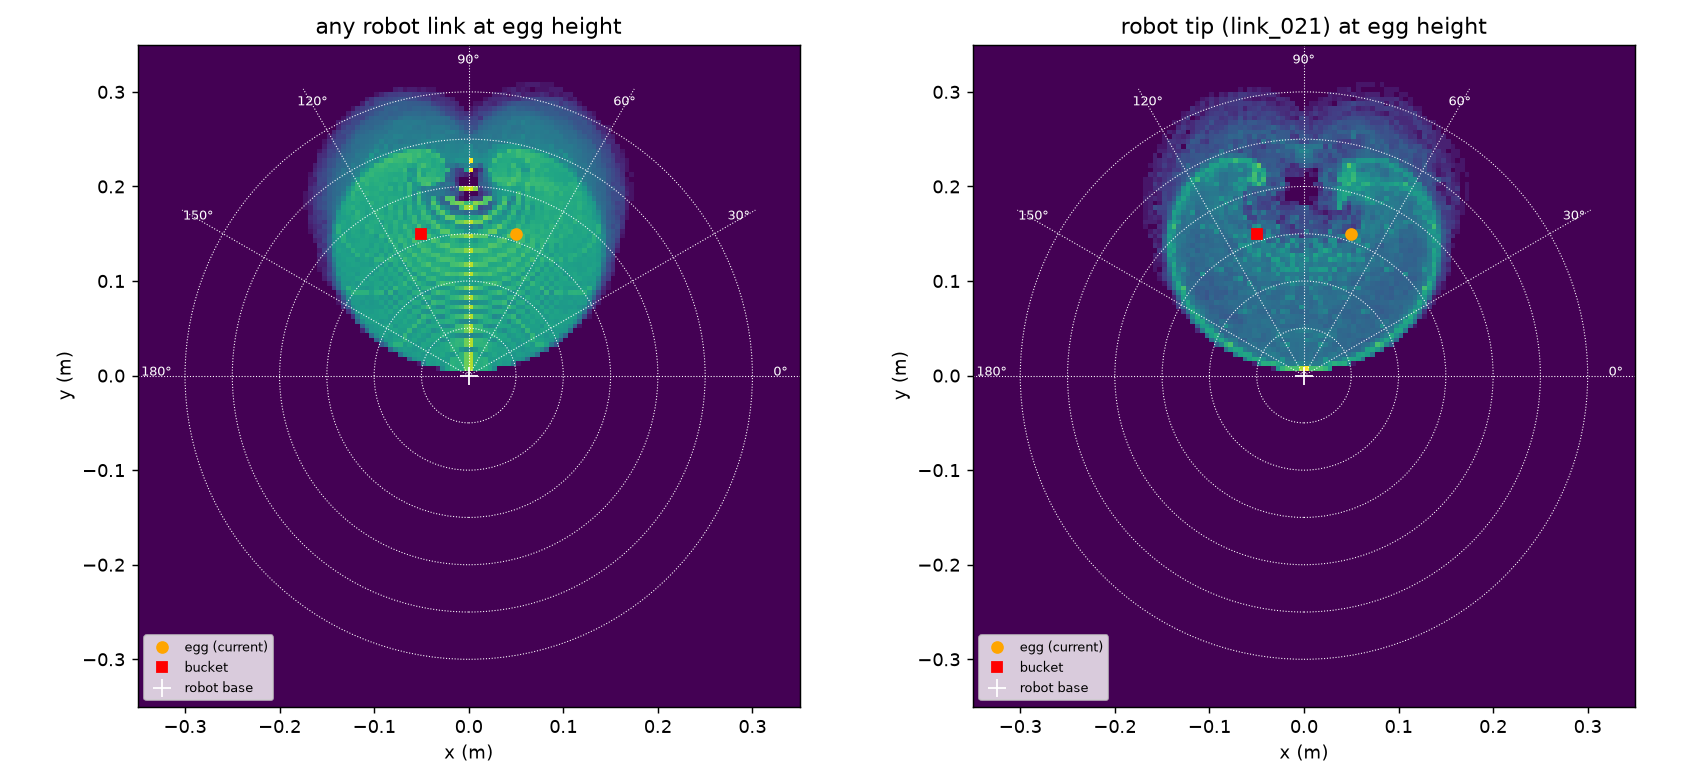

In [ ]:
!cd {REPO} && uv run python tools/workspace_map.py --mode report --out "{OUT}"
from IPython.display import Image, display
display(Image(f"{OUT}/workspace_map.png", width=1000))